In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tqdm

import importlib
import utils.biosensor_mc as biosensor_mc
import utils.biosensor_mc_viz as biosensor_mc_viz
import utils.biosensor_mc_protocols as biosensor_mc_protocols
import utils.generate_geometries as generate_geometries
import utils.save_simulation as save_simulation
importlib.reload(biosensor_mc)
importlib.reload(biosensor_mc_viz)
importlib.reload(biosensor_mc_protocols)
importlib.reload(generate_geometries)
importlib.reload(save_simulation)

from utils.biosensor_mc import *
from utils.biosensor_mc_viz import *
from utils.biosensor_mc_protocols import *
from utils.generate_geometries import *
from utils.save_simulation import *


In [3]:
import matplotlib as mpl
import seaborn as sns

# Seaborn theme
sns.set_theme(
    style="ticks",        # "white", "whitegrid", "ticks", "darkgrid"
    context="paper",       # notebook, paper, talk, poster
    palette="deep"
)

# Your publication formatting
mpl.rcParams.update({

    # Fonts
    "font.family": "Arial",
    "font.size": 24,

    # Figure titles
    "figure.titlesize": 34,
    "figure.titleweight": "bold",

    # Axes titles/labels
    "axes.titlesize": 14,
    "axes.labelsize": 14,

    # Tick labels
    "xtick.labelsize": 14,
    "ytick.labelsize": 14,

    # Legend
    "legend.fontsize": 16,
    "legend.title_fontsize": 18,

    # Lines & markers
    "lines.linewidth": 3,
    "lines.markersize": 8,

    # Axes
    "axes.linewidth": 2,

    # Ticks
    "xtick.major.size": 8,
    "ytick.major.size": 8,
    "xtick.major.width": 2,
    "ytick.major.width": 2,
    "xtick.minor.size": 4,
    "ytick.minor.size": 4,
    "xtick.minor.width": 1.5,
    "ytick.minor.width": 1.5,

    # Grid
    "grid.linewidth": 1,
    "grid.alpha": 0.3,

    # Export
    "figure.dpi": 150,
    "savefig.dpi": 600,

    # Editable vector graphics
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
})

In [726]:
# Run the simulation for a planar surface
# ==========================================================
# Simulation parameters
# ==========================================================

P_planar = Params(
    Lx_m=0.5e-6,
    Ly_m=0.5e-6,
    H_m=0.25e-6,
    a_m=5e-9,

    D_m2_s=1e-11,
    receptor_density_m2=5e15,
    ligand_conc_M=10e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    escape_distance_m=1e-6,

    use_well_mixed_reservoir=True,
    reservoir_offset_layers=1,

    seed=1,
)

# ==========================================================
# Run association step
# ==========================================================

association_time_s = 1

planar_history, planar_state, planar_G, planar_frames = run_simulation(
    P_planar,
    seconds=association_time_s,
    return_state=True,
    save_state_frames=True,
    n_state_frames=20,
    phase_label="association",
)

# ==========================================================
# Run dissociation step
# ==========================================================

from dataclasses import replace

P_planar_dissociation = replace(
    P_planar,
    ligand_conc_M=0.0,
)

dissociation_time_s = 1

planar_history, planar_state, planar_G, planar_frames = run_simulation(
    P_planar_dissociation,
    seconds=dissociation_time_s,
    
    initial_state=planar_state,
    history=planar_history,
    state_frames=planar_frames,

    return_state=True,
    save_state_frames=True,
    n_state_frames=20,
    phase_label="dissociation",
)

Simulation initialization
Phase label          : association
Start time           : 0.000000e+00 s
Start step           : 0
Geometry             : flat
Grid nodes           : 500 x 500 x 251
Accessible fluid     : 250,000 sites
Reactive faces       : 250,000
Reactive area        : 2.500e-13 m^2
Accessible volume    : 2.500e-22 m^3
Receptors            : 1,250
Active ligands       : 0
Mean reservoir count : 1.506e-03
Bulk concentration   : 6.022e+18 molecules/m^3
D                    : 1.000e-11 m^2/s
Mean bulk entries    : 2.384e-04 ligands/step
Well-mixed reservoir : True
Reservoir interface  : 1.500e-09 m (offset=1 layer(s))
Reservoir sites      : 250,000
Receptor density     : 5.000e+15 receptors/m^2
Ligand concentration : 1.000e-08 M
KD                   : 1.000e-07 M
dt                   : 1.583e-08 s
Escape distance      : 1.000e-06 m
Fast receptor grid   : True
RNG preserved        : False


Running association:  70%|██████▉   | 44008931/63157895 [04:52<02:07, 150664.54step/s]


KeyboardInterrupt: 

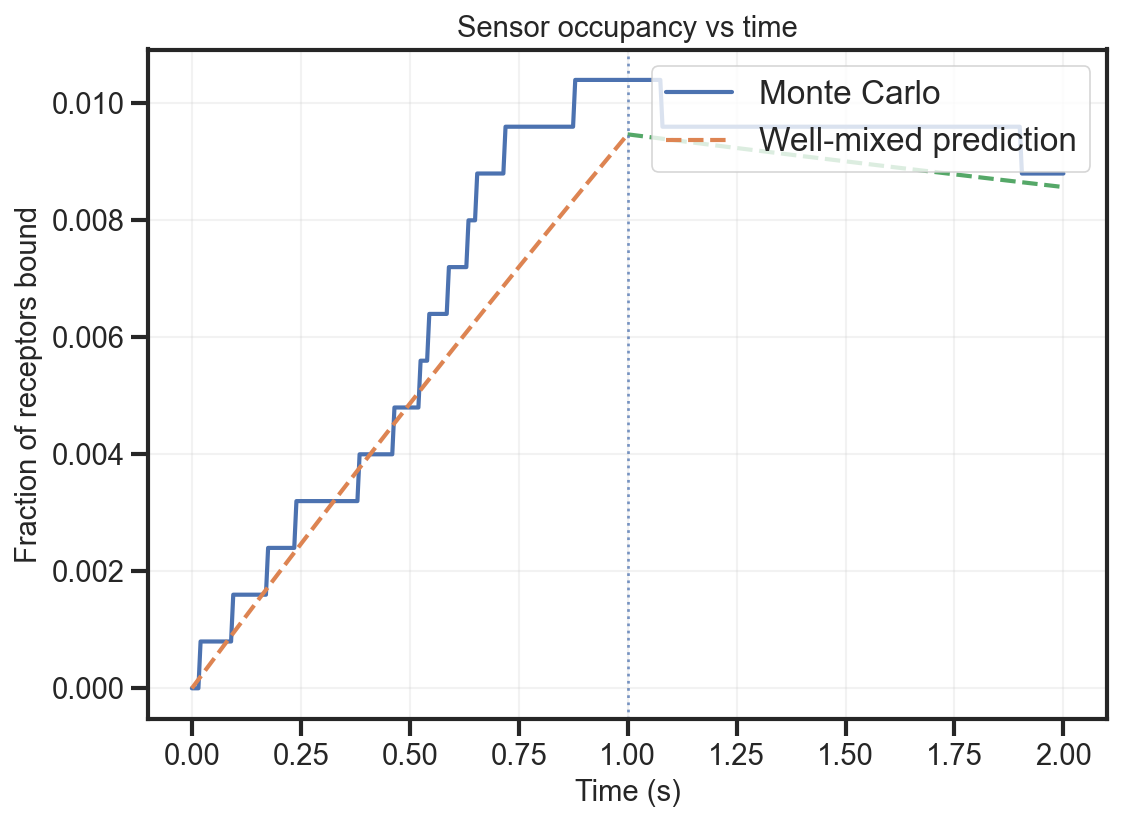

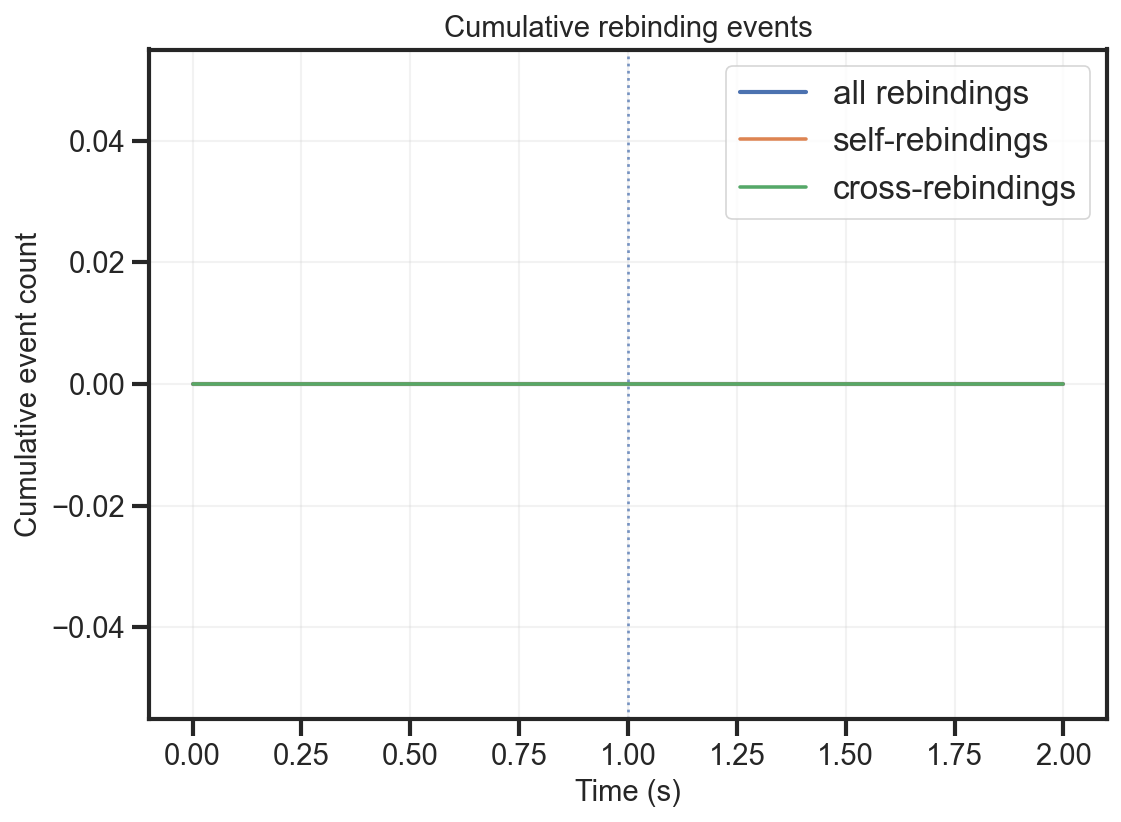

In [725]:
occupancy_fig, occupancy = plot_occupancy(
    planar_history,
    show_langmuir=True,
    show_phase_boundaries=True,
    auto_ylim=True,
    figsize=(8, 6)
)

rebinding_fig, rebinding_events = plot_rebinding_events_over_time(
    planar_history,
    reset_each_phase=False,
    show_phase_boundaries=True,
    normalize=False,
    figsize=(8, 6)
)

plt.show()

In [63]:
# Plot ligand count and exchange balance
# plot_ligand_count(history, figsize=(5, 4))
# plt.show()

# animation = animate_state_frames(planar_frames,
#     figsize=(6, 6),
#     ligand_size=20,
#     receptor_size=20,
#     return_html=True,
#     unbound_receptor_alpha=0.35,
# )

# animation

# # animation.save(
# #     "data/animations/260817/well_mixed_planar_1nM.gif",
# #     writer="pillow",
# #     fps=2,
# # )

In [320]:
P_diffusion = Params(
    Lx_m=1*1e-6,
    Ly_m=1*1e-6,
    H_m=1*1e-6,
    a_m=10*1e-9,

    D_m2_s=1*1e-11,
    receptor_density_m2=100*1e12,
    ligand_conc_M=1*1e-9,

    k_on_M_inv_s=1e7,
    k_off_s=0.1,

    seed=1,
)

diffusion_result = run_free_diffusion_protocol(
    P_diffusion,
    seconds=0.5,
    n_particles=1000,
    n_records=101,
    seed=1,
    save_history_csv="data/diffusion_validation/free_diffusion_validation_D1e-10.csv",
)

/Users/rynon/Documents/GitHub/SensorModeling/utils/biosensor_mc.py:385: RuntimeWarning: SciPy is unavailable; using a Manhattan-distance approximation for rebinding escape distance.
  accessible_fluid_mask=accessible_fluid_mask,


Free-diffusion validation
Particles                 : 1,000
Steps                     : 315,790
Requested duration        : 5.000000e-01 s
Actual duration           : 5.000008e-01 s
Lattice spacing           : 1.000000e-08 m
Timestep                  : 1.583333e-06 s
Input D                   : 1.000000e-11 m^2/s
Kernel D                  : 1.000000e-11 m^2/s
MSD-fit D                 : 1.031169e-11 m^2/s
Relative fitted-D error   : 3.117%
Theoretical final RMS     : 5.477230e-06 m


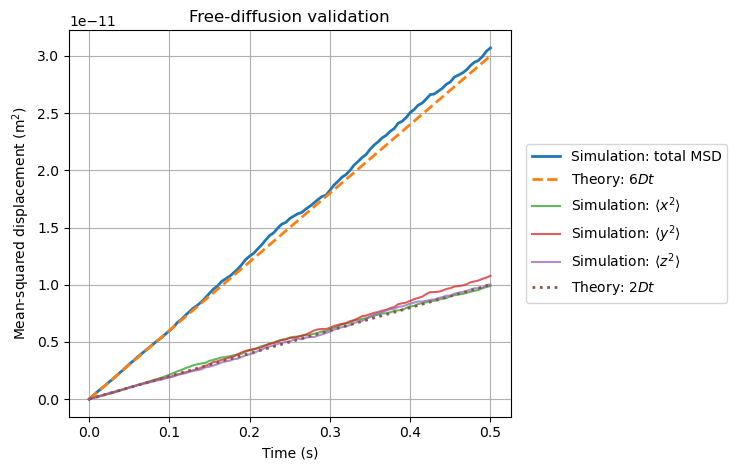

In [323]:
fig, ax = plot_msd_validation(diffusion_result)

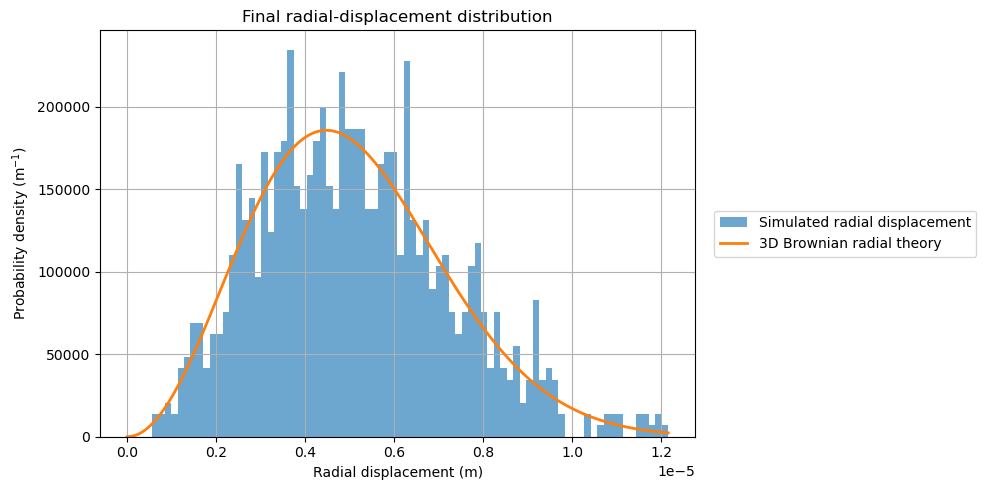

In [324]:
fig, ax = plot_radial_displacement_distribution(
    diffusion_result,
    bins=80,
    figsize=(10, 5)
)

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'cylindrical_well: z slice at index 20 (2.000e-07 m)'}, xlabel='x (m)', ylabel='y (m)'>)

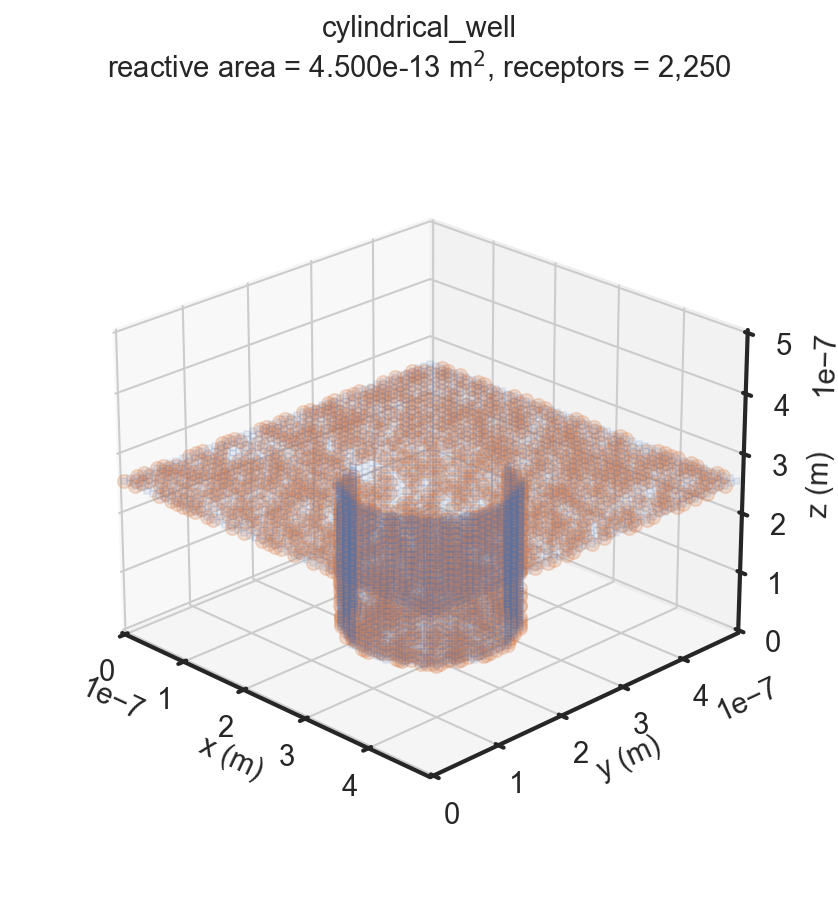

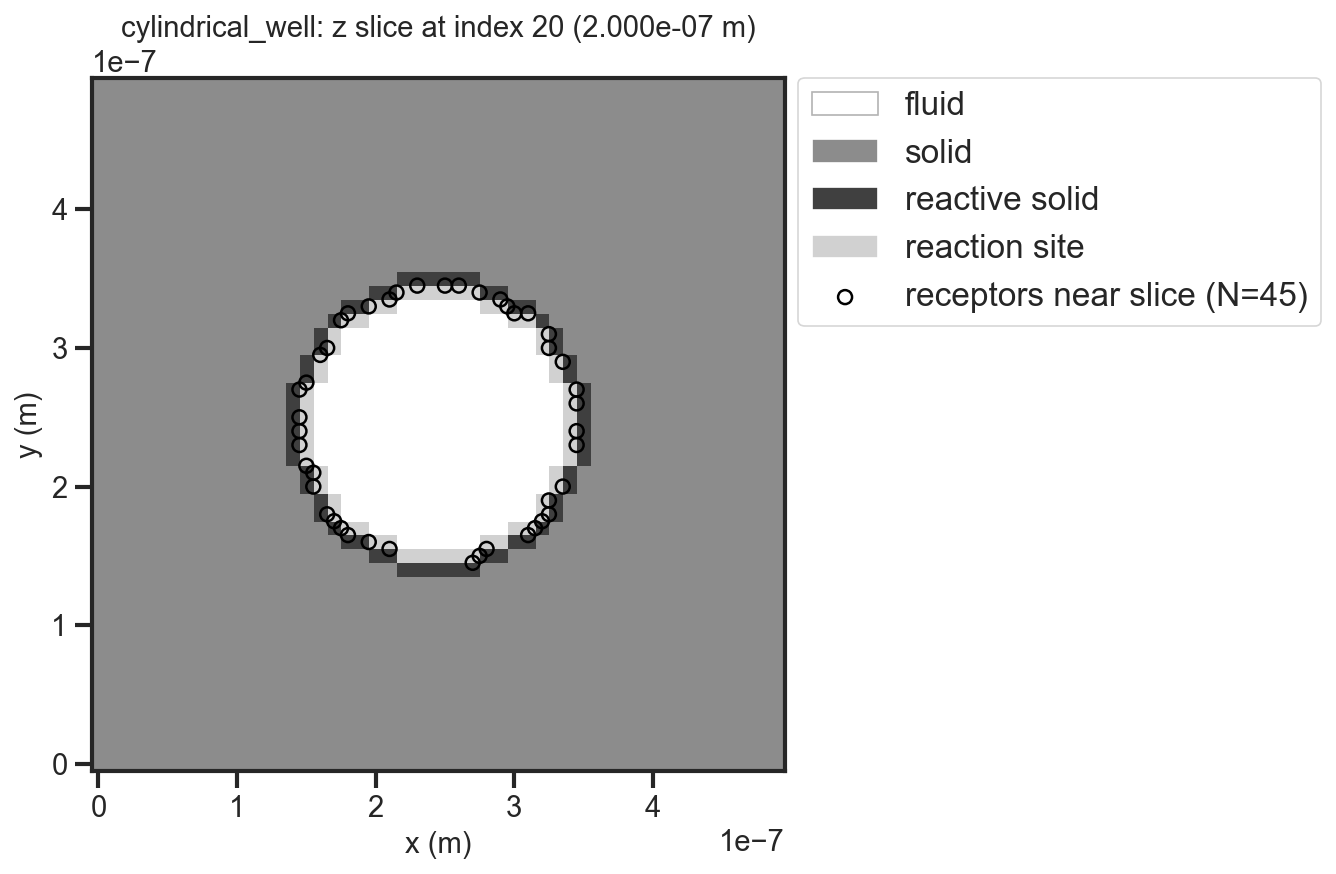

In [632]:
P_cylindrical = Params(
    Lx_m=0.5e-6,
    Ly_m=0.5e-6,
    H_m=0.5e-6,
    a_m=10e-9,

    D_m2_s=1*1e-11,
    receptor_density_m2=5e15,
    ligand_conc_M=1*1e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    seed=1,
)

cylindrical_geometry = make_cylindrical_well_geometry(
    P_cylindrical,
    radius_m=100e-9,
    depth_m=250e-9
)

G_cylindrical, S_cylindrical = prepare_geometry_inspection(
    P_cylindrical,
    geometry=cylindrical_geometry,
)

plot_geometry_receptors_3d(
    P_cylindrical,
    G=G_cylindrical,
    S=S_cylindrical,
    max_surface_points=50_000,
    show_reactive_surface=False,
    surface_alpha=0.1,
    receptor_alpha=0.25,
    show_legend=False,
    azim=-45,
    zoom=0.85,
    figsize=(10, 7)
)

plot_geometry_slice(
    P_cylindrical,
    G=G_cylindrical,
    S=S_cylindrical,
    axis="z",
    coordinate_m=200e-9,
)

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'spherical_cap: z slice at index 0 (0.000e+00 m)'}, xlabel='x (m)', ylabel='y (m)'>)

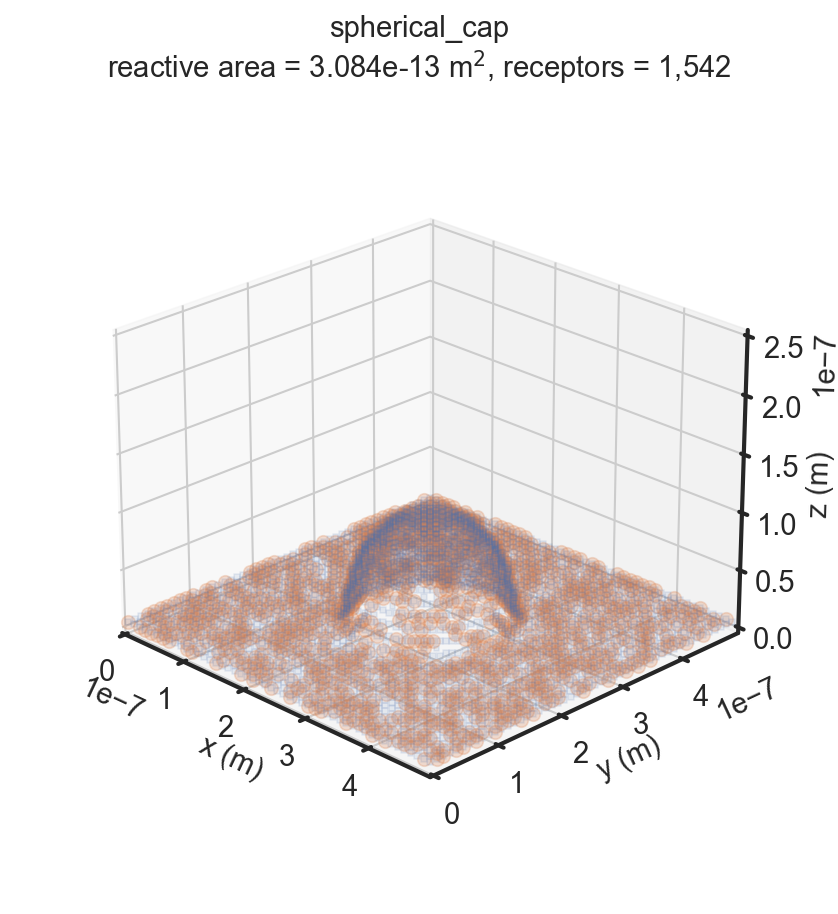

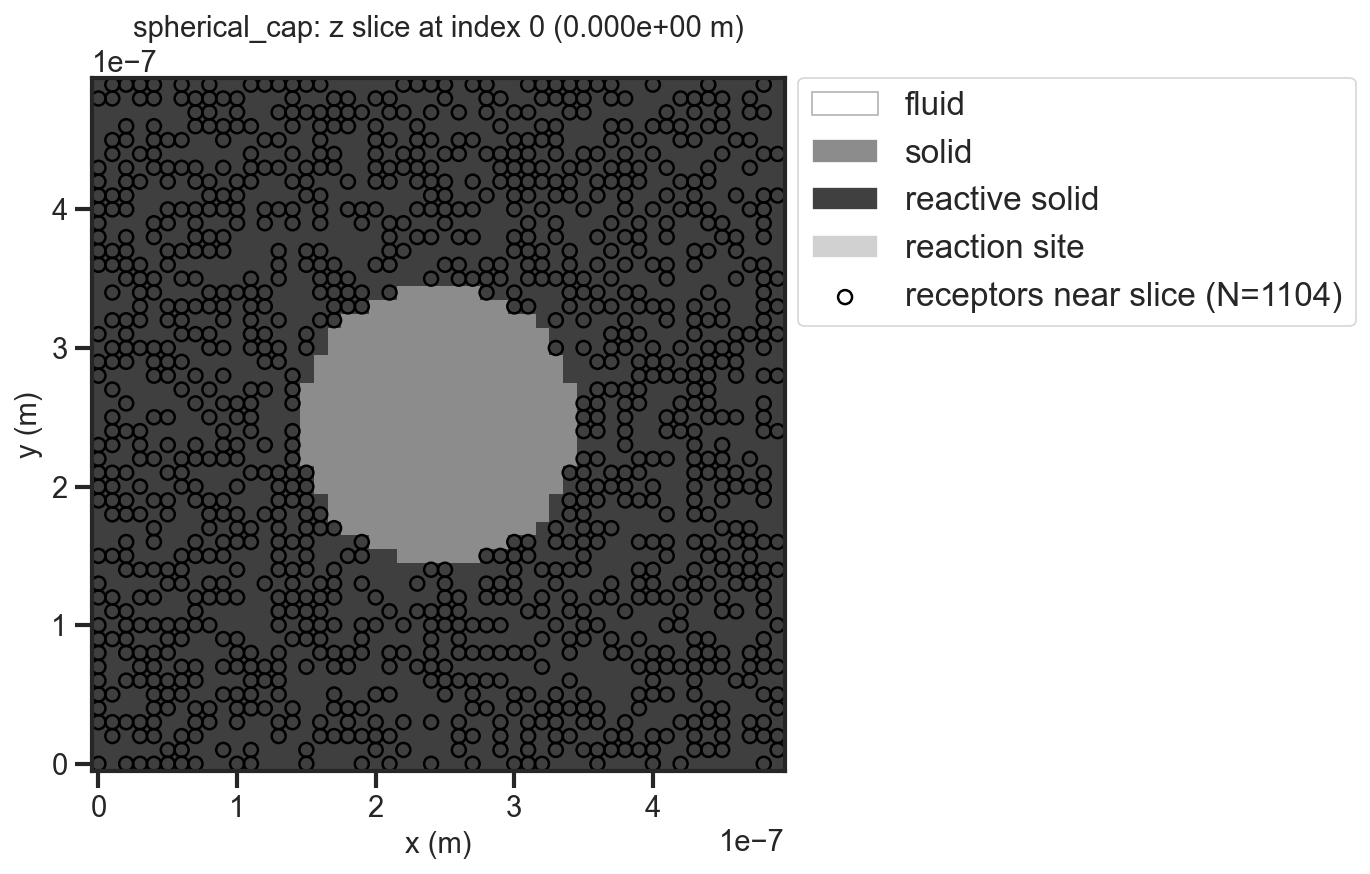

In [633]:
P_cap = Params(
    Lx_m=0.5e-6,
    Ly_m=0.5e-6,
    H_m=0.25e-6,
    a_m=10e-9,

    D_m2_s=1*1e-11,
    receptor_density_m2=5e15,
    ligand_conc_M=1*1e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    seed=1,
)

cap_geometry = make_spherical_cap_geometry(
    P_cap,
    radius_m=100e-9,
    cap_height_m=100e-9
)

G_cap, S_cap = prepare_geometry_inspection(
    P_cap,
    geometry=cap_geometry,
)

plot_geometry_receptors_3d(
    P_cap,
    G=G_cap,
    S=S_cap,
    max_surface_points=50_000,
    show_reactive_surface=False,
    surface_alpha=0.1,
    receptor_alpha=0.25,
    show_legend=False,
    azim=-45,
    zoom=0.85,
    figsize=(10, 7)
)

plot_geometry_slice(
    P_cap,
    G=G_cap,
    S=S_cap,
    axis="z",
    coordinate_m=0e-9,
)

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'cylindrical_post: z slice at index 0 (0.000e+00 m)'}, xlabel='x (m)', ylabel='y (m)'>)

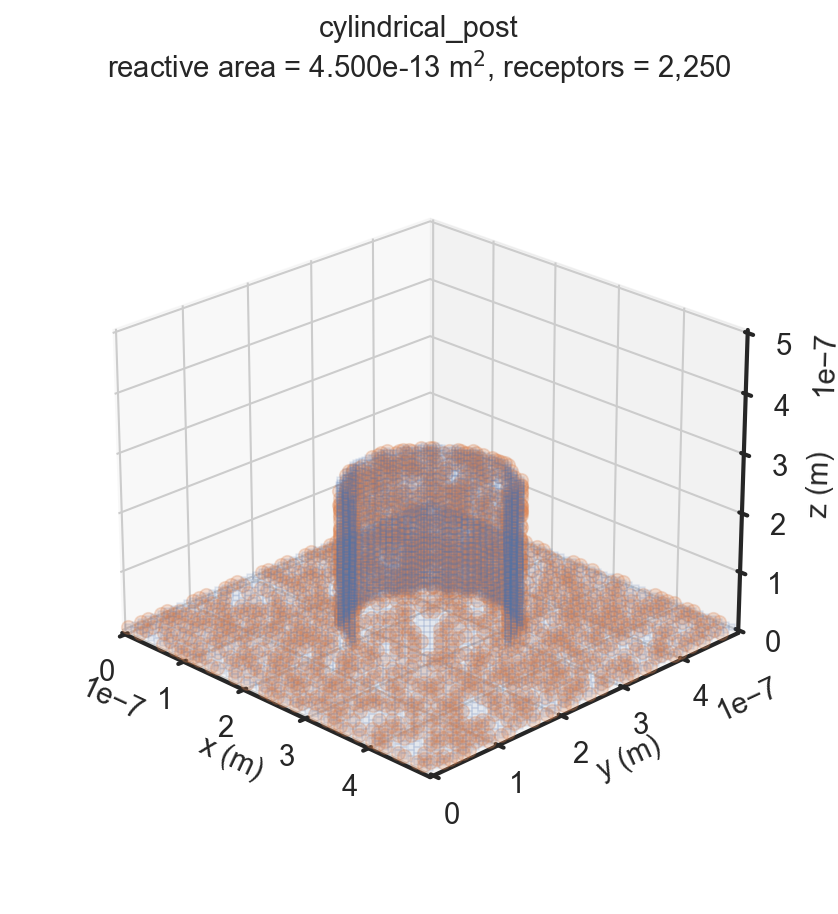

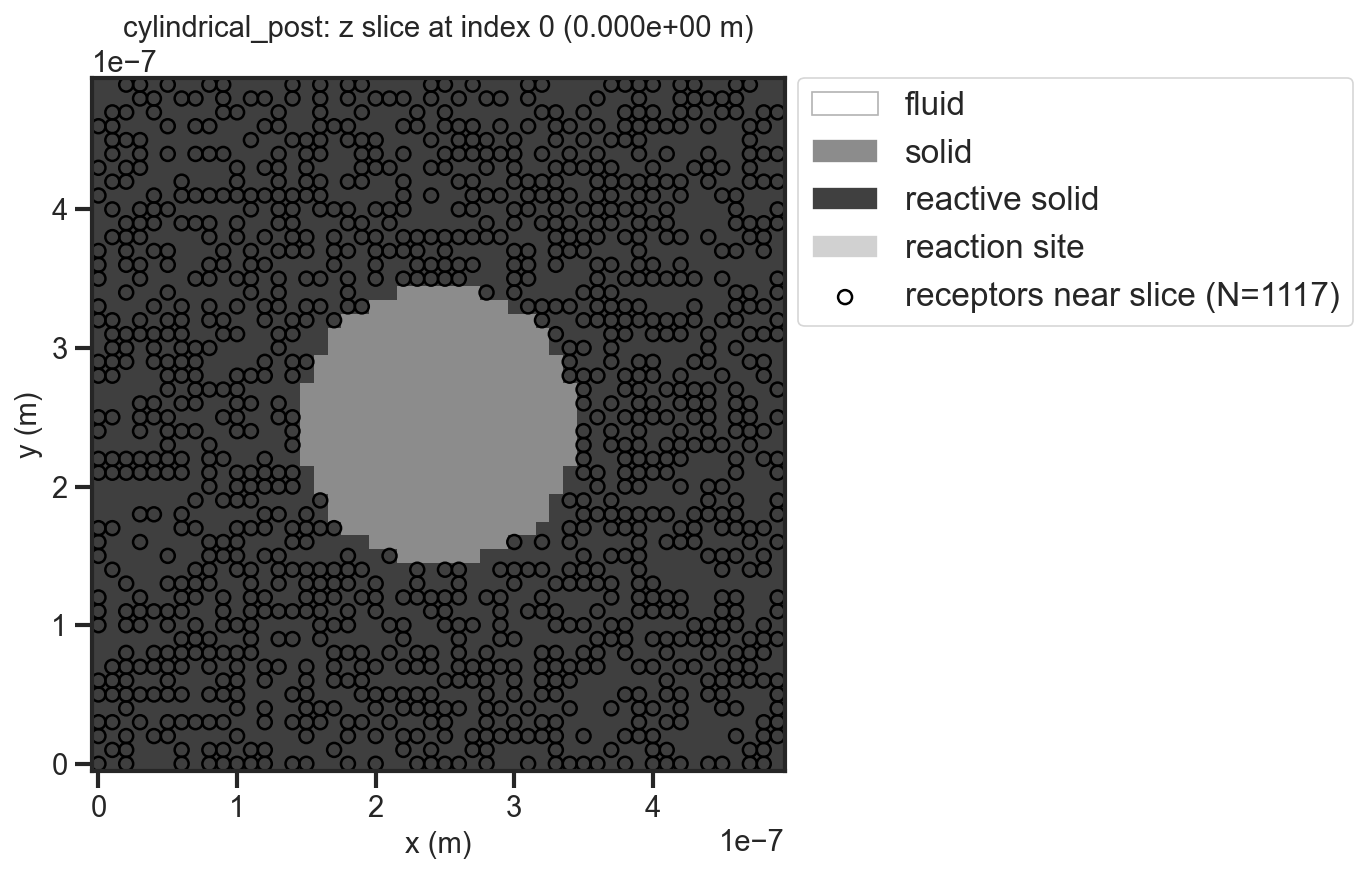

In [634]:
P_post = Params(
    Lx_m=0.5e-6,
    Ly_m=0.5e-6,
    H_m=0.5e-6,
    a_m=10e-9,

    D_m2_s=1*1e-11,
    receptor_density_m2=5e15,
    ligand_conc_M=1*1e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    seed=1,
)

post_geometry = make_cylindrical_post_geometry(
    P_post,
    radius_m=100e-9,
    height_m=250e-9
)

G_post, S_post = prepare_geometry_inspection(
    P_post,
    geometry=post_geometry,
)

plot_geometry_receptors_3d(
    P_post,
    G=G_post,
    S=S_post,
    max_surface_points=50_000,
    show_reactive_surface=False,
    surface_alpha=0.1,
    receptor_alpha=0.25,
    show_legend=False,
    azim=-45,
    zoom=0.85,
    figsize=(10, 7)
)

plot_geometry_slice(
    P_post,
    G=G_post,
    S=S_post,
    axis="z",
    coordinate_m=0e-9,
)

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'flat: z slice at index 1 (1.000e-09 m)'}, xlabel='x (m)', ylabel='y (m)'>)

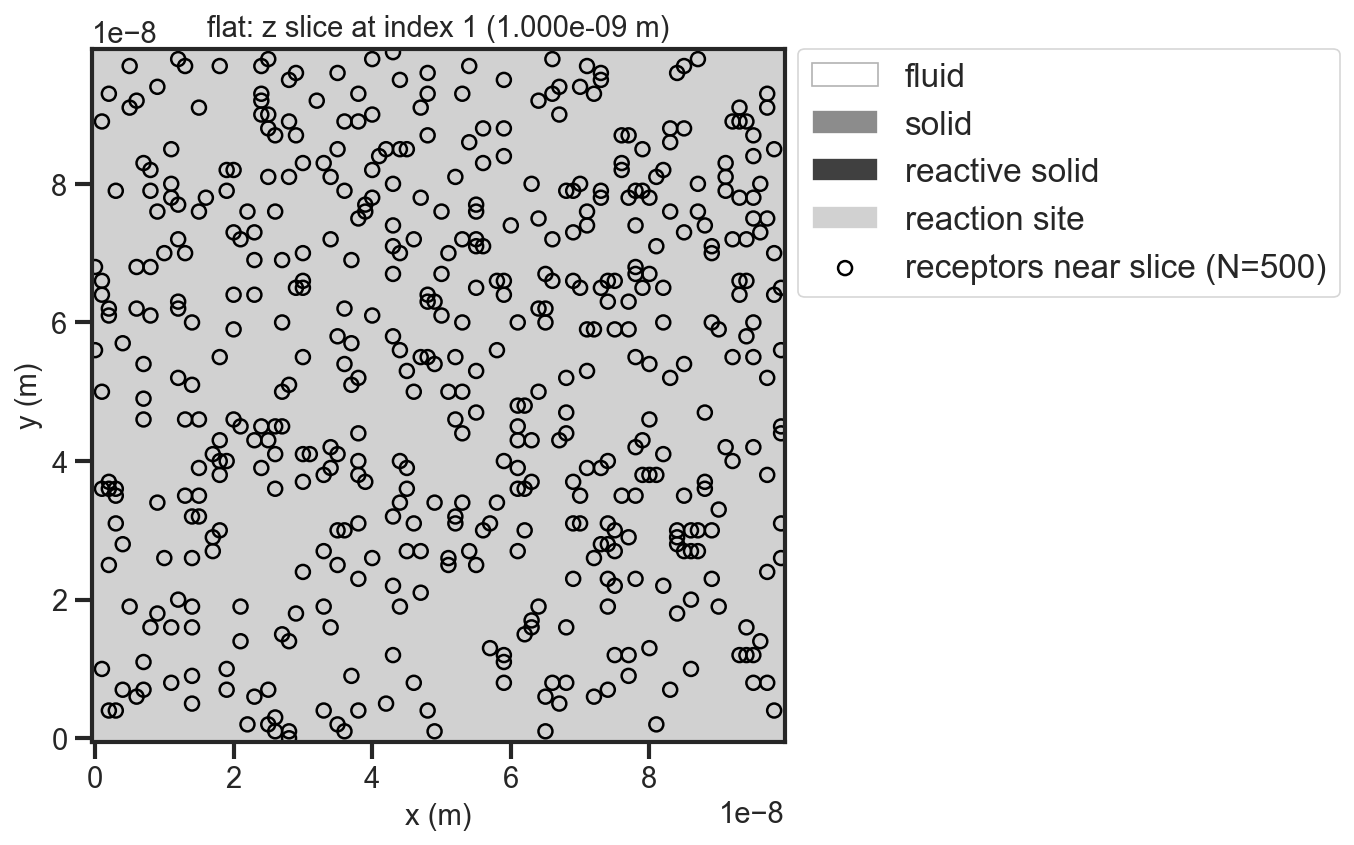

In [8]:
P_bowl = Params(
    Lx_m=0.1e-6,
    Ly_m=0.1e-6,
    H_m=0.1e-6,
    a_m=1e-9,

    D_m2_s=1*1e-11,
    receptor_density_m2=5e16,
    ligand_conc_M=1*1e-9,

    k_on_M_inv_s=1e8,
    k_off_s=1e-1,

    seed=1,
)

G_bowl = make_spherical_bowl_geometry(
    P_bowl,
    radius_m=5e-9,
    depth_m=5e-9
)

# plotter = plot_geometry_receptors_3d(
#     P_nanospike,
#     geometry=nanospike_geometry,
#     show_receptors=False,
#     show_reservoir=True,
#     enable_clipping=True,
#     show_legend=False,

#     receptor_size=10,
#     surface_alpha=0.75,

#     window_size=(600, 600)
# )

plot_geometry_slice(
    P_bowl,
    G=G_bowl,
    axis="z",
    coordinate_m=1e-9,
)

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'nanopore_array: z slice at index 20 (1.000e-07 m)'}, xlabel='x (m)', ylabel='y (m)'>)

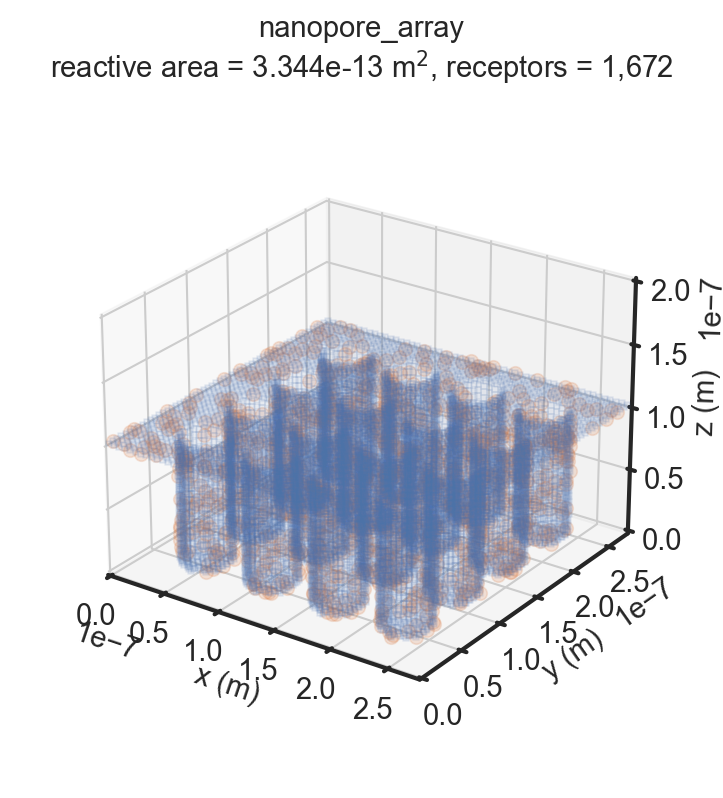

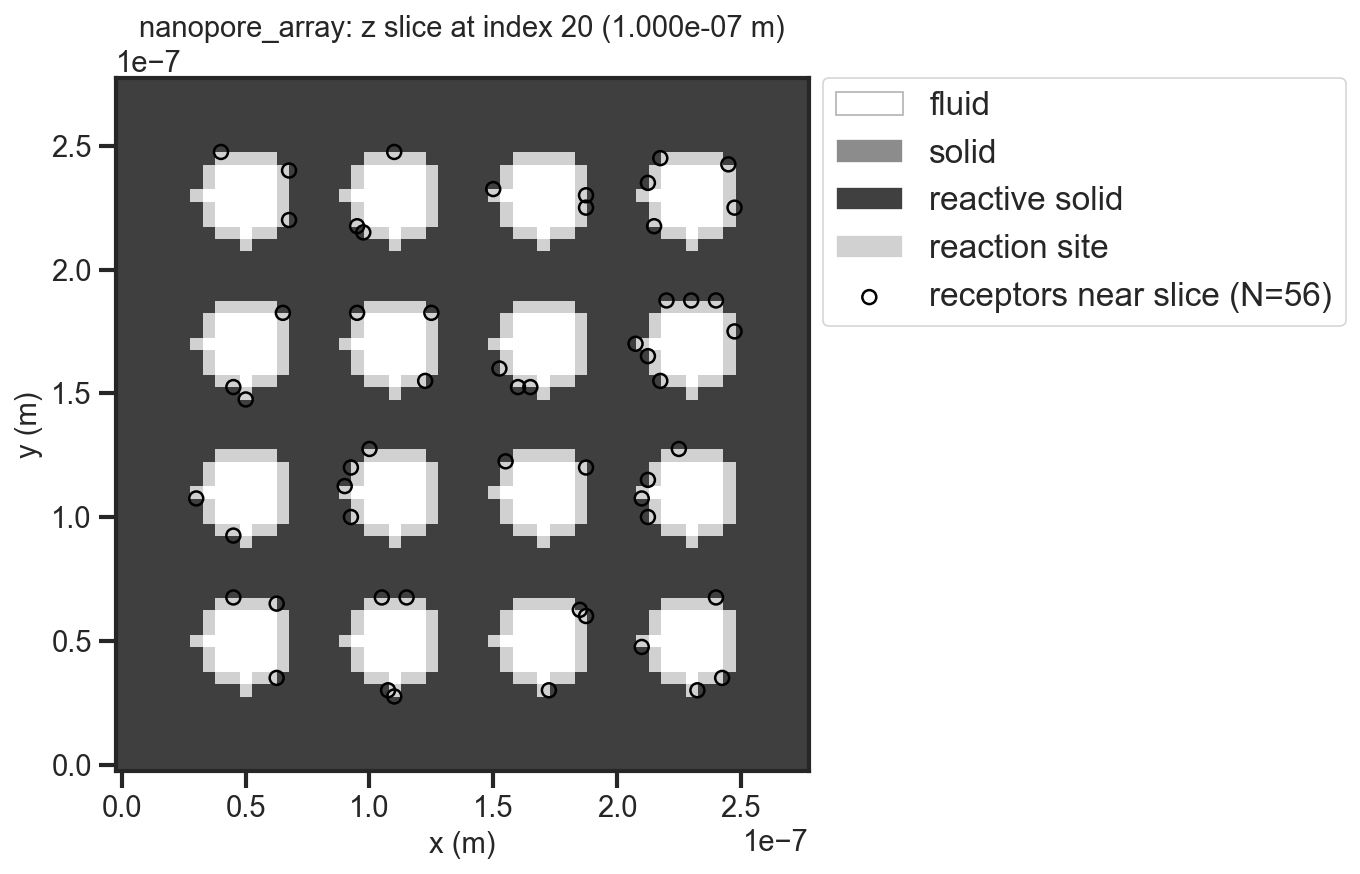

In [ ]:
P_nanoporous = Params(
    Lx_m=0.28e-6,
    Ly_m=0.28e-6,
    H_m=0.2e-6,
    a_m=5e-9,

    D_m2_s=1e-11,
    receptor_density_m2=5e15,
    ligand_conc_M=10e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    escape_distance_m=1e-6,

    use_well_mixed_reservoir=True,
    reservoir_offset_layers=1,

    seed=1,
)

nanopore_geometry = make_nanopore_array_geometry(
    P_nanoporous,
    pore_diameter_m=40e-9,
    pore_depth_m=100e-9,
    pitch_m=60e-9,
    rim_z_m=100e-9,
    layout="square",
)

G_nanoporous, S_nanoporous = prepare_geometry_inspection(
    P_nanoporous,
    geometry=nanopore_geometry,
)

plot_geometry_slice(
    P_nanoporous,
    G=G_nanoporous,
    S=S_nanoporous,
    axis="z",
    coordinate_m=100e-9,
)

In [705]:
# ==========================================================
# Run nanoporous geometry simulation
# ==========================================================

simulation_time_np_s = 60

nanoporous_history, nanoporous_state, nanoporous_G, nanoporous_frames = run_simulation(
    P_nanoporous,
    seconds=simulation_time_np_s,
    geometry=nanopore_geometry,
    show_progress=True,
    verbose=True,

    save_state_frames=True,
    n_state_frames=20,
    return_state=True,

    phase_label="association_10nM"
)

Simulation initialization
Phase label          : association_10nM
Start time           : 0.000000e+00 s
Start step           : 0
Geometry             : nanopore_array
Grid nodes           : 20 x 20 x 51
Accessible fluid     : 1,200 sites
Reactive faces       : 1,200
Reactive area        : 1.200e-13 m^2
Accessible volume    : 1.200e-21 m^3
Receptors            : 600
Active ligands       : 0
Mean reservoir count : 7.227e-03
Bulk concentration   : 6.022e+18 molecules/m^3
D                    : 1.000e-11 m^2/s
Mean bulk entries    : 3.814e-04 ligands/step
Well-mixed reservoir : True
Reservoir interface  : 1.150e-07 m (offset=1 layer(s))
Reservoir sites      : 400
Receptor density     : 5.000e+15 receptors/m^2
Ligand concentration : 1.000e-08 M
KD                   : 1.000e-07 M
dt                   : 1.583e-06 s
Escape distance      : 1.000e-06 m
Fast receptor grid   : False
RNG preserved        : False


Running association_10nM: 100%|██████████| 37894737/37894737 [10:17<00:00, 61346.27step/s]


Completed phase 'association_10nM': 37,894,737 steps, t = 6.000000e+01 s.


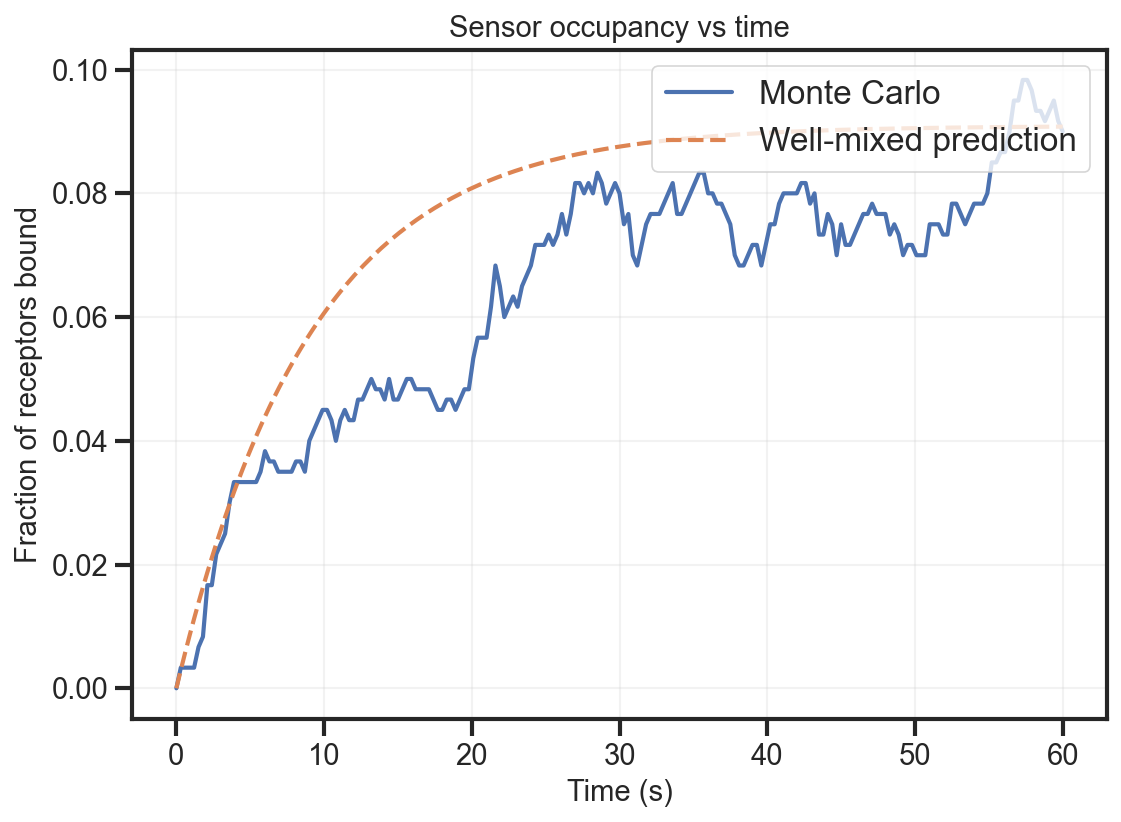

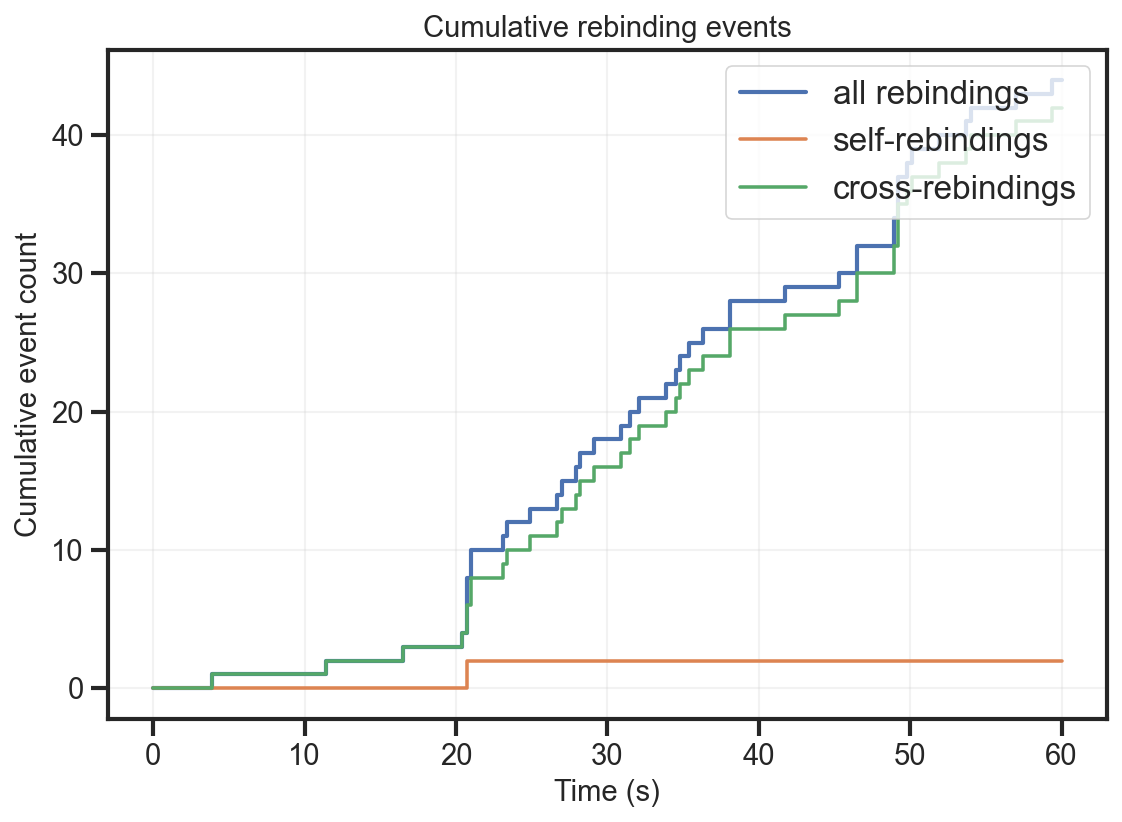

In [706]:
occupancy_fig, occupancy = plot_occupancy(
    nanoporous_history,
    show_langmuir=True,
    show_phase_boundaries=True,
    auto_ylim=True,
    figsize=(8, 6)
)

rebinding_fig, rebinding_events = plot_rebinding_events_over_time(
    nanoporous_history,
    reset_each_phase=False,
    show_phase_boundaries=True,
    normalize=False,
    figsize=(8, 6)
)

plt.show()

In [62]:
# nanoporous_animation = animate_state_frames(
#     nanoporous_frames,
#     interval=250,
#     show_surface=True,
#     show_release_sites=False,
#     return_html=True,
#     unbound_receptor_alpha=0.25,
#     figsize=(5,5)
# )

# nanoporous_animation

# nanoporous_animation.save(
#     "data/animations/nanoporous_kon1e7_koff-1_1nM_500s.gif",
#     writer="pillow",
#     fps=2,
# )

In [19]:
from utils.generate_geometries import make_dendritic_nanospike_geometry

P_nanospike =  Params(
    Lx_m=0.25e-6,
    Ly_m=0.25e-6,
    H_m=0.25e-6,
    a_m=5e-9,

    D_m2_s=1e-11,
    receptor_density_m2=5e15,
    ligand_conc_M=10e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    escape_distance_m=1e-6,

    use_well_mixed_reservoir=True,
    reservoir_offset_layers=1,

    seed=1,
)

nanospike_geometry = make_dendritic_nanospike_geometry(
    P_nanospike,

    base_z_m=0.0,

    # Primary trunks
    spike_density_m2=5e14,

    primary_height_mean_m=100e-9,
    primary_height_sd_m=25e-9,

    primary_base_radius_mean_m=10e-9,
    primary_base_radius_sd_m=3e-9,

    primary_tip_radius_mean_m=5e-9,
    primary_tip_radius_sd_m=1e-9,

    primary_tilt_mean_deg=10,
    primary_tilt_sd_deg=5,

    # Dendritic branching
    branch_levels=3,
    branches_per_segment_mean=5,

    branch_origin_fraction_range=(0.10, 0.9),

    branch_length_fraction_mean=0.5,
    branch_length_fraction_sd=0.10,

    branch_angle_mean_deg=45,
    branch_angle_sd_deg=10,

    branch_radius_fraction=0.50,
    branch_tip_radius_fraction=0.35,

    geometry_seed=1,
)

# plotter = plot_geometry_receptors_3d(
#     P_nanospike,
#     geometry=nanospike_geometry,
#     show_receptors=False,
#     show_reservoir=True,
#     enable_clipping=True,
#     show_legend=False,

#     receptor_size=10,
#     surface_alpha=0.75,

#     window_size=(600, 600)
# )

plot_geometry_slice(
    P_nanospike,
    G=nanospike_geometry,
    S=S_nanospike,
    axis="y",
    coordinate_m=125e-9,
)

AttributeError: 'SensorGeometry' object has no attribute 'grid_shape'

In [11]:
import pyvista as pv
import vtk
import trame
from importlib.metadata import version

print("PyVista:", pv.__version__)
print("VTK:", vtk.vtkVersion.GetVTKVersion())
print("trame:", version("trame"))

PyVista: 0.48.4
VTK: 9.6.2
trame: 3.13.2


In [767]:
# ==========================================================
# Run association step
# ==========================================================

association_time_s = 5

nanospike_history, nanospike_state, nanospike_G, nanospike_frames = run_simulation(
    P_nanospike,
    seconds=association_time_s,
    geometry=nanospike_geometry,
    return_state=True,
    save_state_frames=True,
    n_state_frames=10,
    phase_label="association",
)

# ==========================================================
# Run dissociation step
# ==========================================================

from dataclasses import replace

P_nanospike_dissociation = replace(
    P_nanospike,
    ligand_conc_M=0.0,
)

dissociation_time_s = 5

nanospike_history, nanospike_state, nanospike_G, nanospike_frames = run_simulation(
    P_nanospike_dissociation,
    seconds=dissociation_time_s,
    
    initial_state=nanospike_state,
    history=nanospike_history,
    state_frames=nanospike_frames,
    geometry=nanospike_geometry,
    return_state=True,
    save_state_frames=True,
    n_state_frames=10,
    phase_label="dissociation",
)

Simulation initialization
Phase label          : association
Start time           : 0.000000e+00 s
Start step           : 0
Geometry             : dendritic_nanospike_planar
Grid nodes           : 50 x 50 x 51
Accessible fluid     : 80,009 sites
Reactive faces       : 13,704
Reactive area        : 3.426e-13 m^2
Accessible volume    : 1.000e-20 m^3
Receptors            : 1,713
Active ligands       : 0
Mean reservoir count : 6.023e-02
Bulk concentration   : 6.022e+18 molecules/m^3
D                    : 1.000e-11 m^2/s
Mean bulk entries    : 2.980e-04 ligands/step
Well-mixed reservoir : True
Reservoir interface  : 1.725e-07 m (offset=1 layer(s))
Reservoir sites      : 2,500
Receptor density     : 5.000e+15 receptors/m^2
Ligand concentration : 1.000e-08 M
KD                   : 1.000e-07 M
dt                   : 3.958e-07 s
Escape distance      : 1.000e-06 m
Fast receptor grid   : False
RNG preserved        : False


Running association: 100%|██████████| 12631579/12631579 [05:32<00:00, 37964.39step/s]


Completed phase 'association': 12,631,579 steps, t = 5.000000e+00 s.
Simulation continuation
Phase label          : dissociation
Start time           : 5.000000e+00 s
Start step           : 12,631,579
Geometry             : dendritic_nanospike_planar
Grid nodes           : 50 x 50 x 51
Accessible fluid     : 80,009 sites
Reactive faces       : 13,704
Reactive area        : 3.426e-13 m^2
Accessible volume    : 1.000e-20 m^3
Receptors            : 1,713
Active ligands       : 63
Mean reservoir count : 0.000e+00
Bulk concentration   : 0.000e+00 molecules/m^3
D                    : 1.000e-11 m^2/s
Mean bulk entries    : 0.000e+00 ligands/step
Well-mixed reservoir : True
Reservoir interface  : 1.725e-07 m (offset=1 layer(s))
Reservoir sites      : 2,500
Receptor density     : 5.000e+15 receptors/m^2
Ligand concentration : 0.000e+00 M
KD                   : 1.000e-07 M
dt                   : 3.958e-07 s
Escape distance      : 1.000e-06 m
Fast receptor grid   : False
RNG preserved        : Tr

Running dissociation: 100%|██████████| 12631579/12631579 [07:40<00:00, 27458.18step/s]

Completed phase 'dissociation': 12,631,579 steps, t = 1.000000e+01 s.


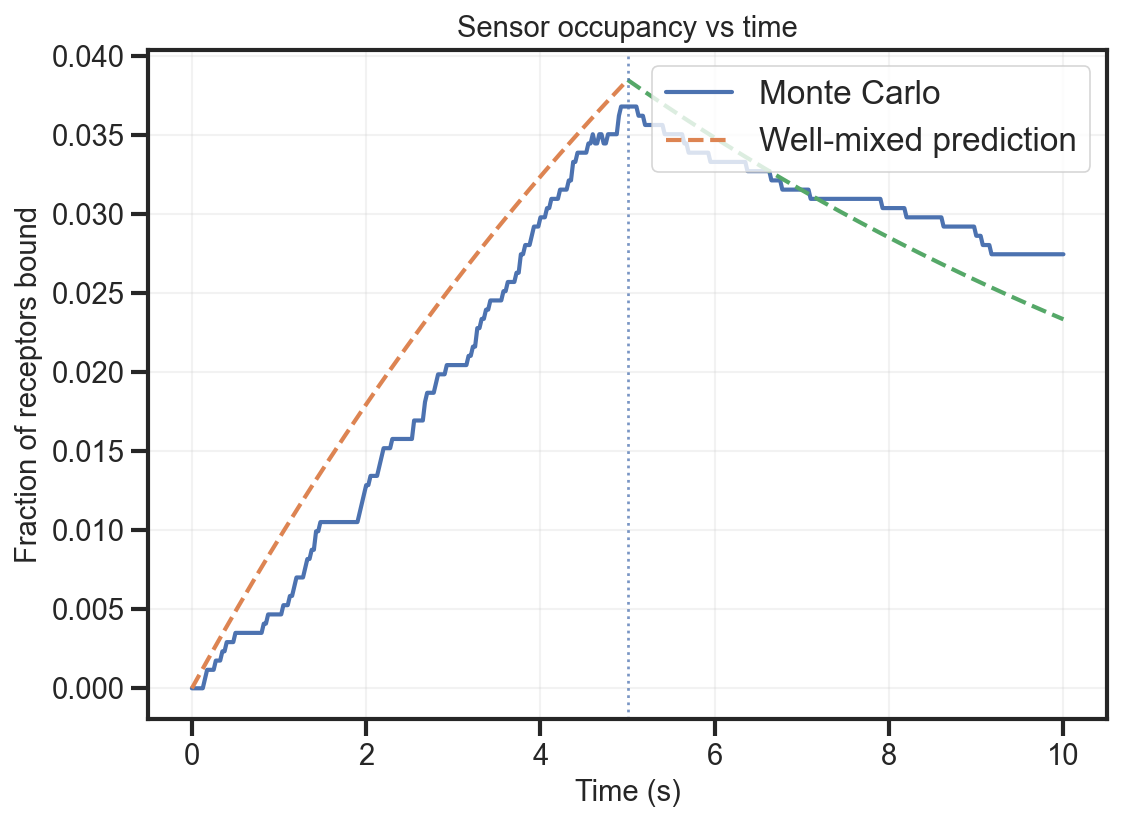

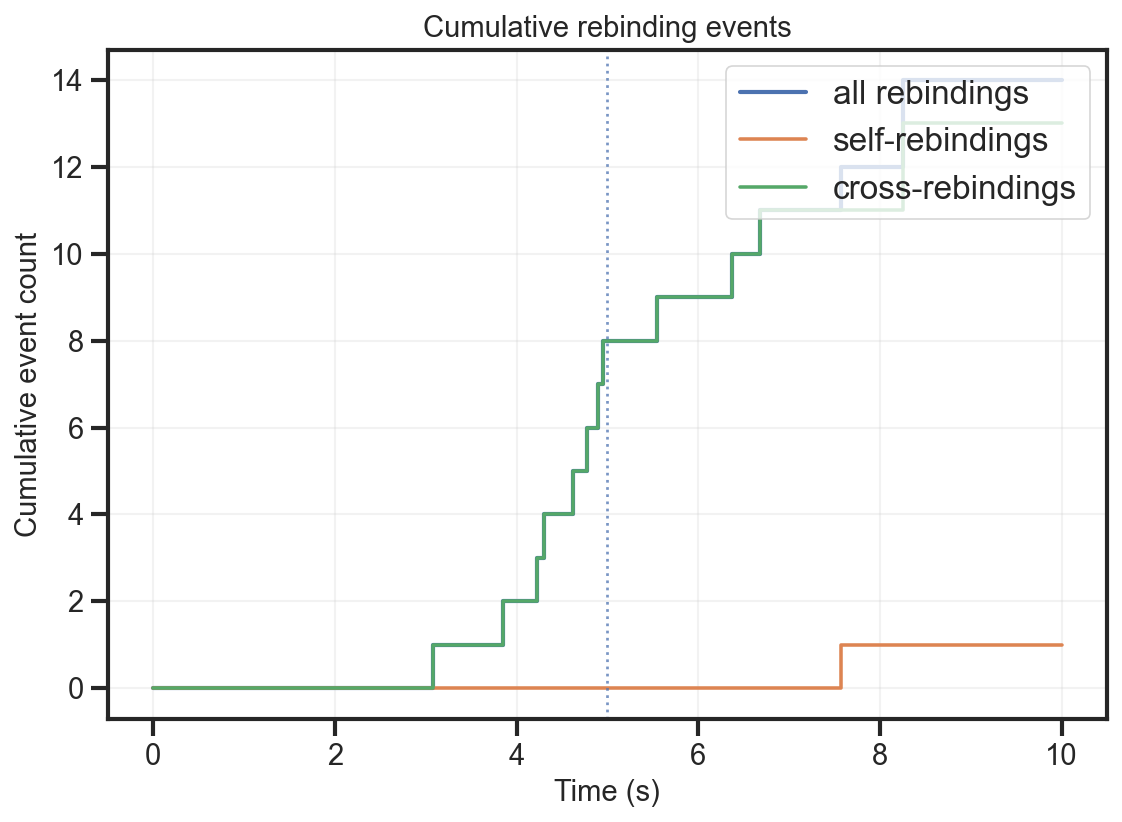

In [768]:
occupancy_fig, occupancy = plot_occupancy(
    nanospike_history,
    show_langmuir=True,
    show_phase_boundaries=True,
    auto_ylim=True,
    figsize=(8, 6)
)

rebinding_fig, rebinding_events = plot_rebinding_events_over_time(
    nanospike_history,
    reset_each_phase=False,
    show_phase_boundaries=True,
    normalize=False,
    figsize=(8, 6)
)

plt.show()

In [770]:
nanospike_animation = animate_state_frames(
    nanospike_frames,
    interval=250,
    show_surface=False,
    show_release_sites=False,
    return_html=False,
    unbound_receptor_alpha=0.01,
    figsize=(8,8)
)

# nanospike_animation

# nanospike_animation.save(
#     "data/animations/nanospike_kon1e6_koff-1_10nM_5s.gif",
#     writer="pillow",
#     fps=2,
# )

(<Figure size 800x600 with 1 Axes>,
 <Axes: title={'center': 'funnel_trap: y slice at index 25 (1.250e-07 m)'}, xlabel='x (m)', ylabel='z (m)'>)

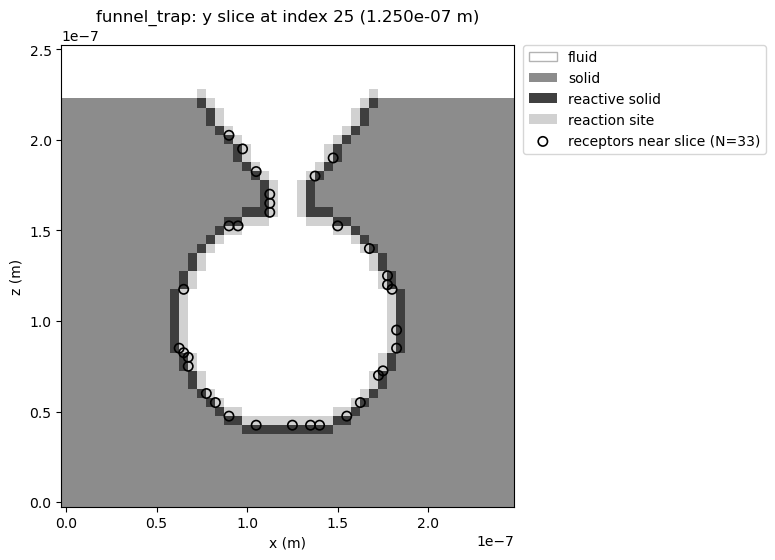

In [50]:
from utils.generate_geometries import make_funnel_trap_geometry

P_trap =  Params(
    Lx_m=0.25e-6,
    Ly_m=0.25e-6,
    H_m=0.25e-6,
    a_m=5e-9,

    D_m2_s=1e-11,
    receptor_density_m2=1e16,
    ligand_conc_M=10e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    escape_distance_m=1e-6,

    use_well_mixed_reservoir=True,
    reservoir_offset_layers=1,

    seed=1,
)


trap_geometry = make_funnel_trap_geometry(
    P_trap,

    surface_z_m=220e-9,

    cavity_radius_m=60e-9,

    funnel_depth_m=45e-9,
    funnel_mouth_radius_m=45e-9,
    funnel_throat_radius_m=12e-9,

    throat_length_m=20e-9,

    reactive_region="trap_only",

    name="funnel_trap",
)

# plotter = plot_geometry_receptors_3d(
#     P_trap,
#     geometry=trap_geometry,
#     show_receptors=True,
#     show_reservoir=True,
#     enable_clipping=True,
#     show_legend=False,

#     receptor_size=10,
#     surface_alpha=0.75,

#     window_size=(600, 600)
# )

G_trap, S_trap = prepare_geometry_inspection(
    P_trap,
    geometry=trap_geometry,
)

plot_geometry_slice(
    P_trap,

    G=G_trap,
    S=S_trap,
    axis="y",
    coordinate_m=125e-9,
)

(<Figure size 1200x900 with 1 Axes>,
 <Axes: title={'center': 'funnel_trap_array: y slice at index 40 (2.000e-07 m)'}, xlabel='x (m)', ylabel='z (m)'>)

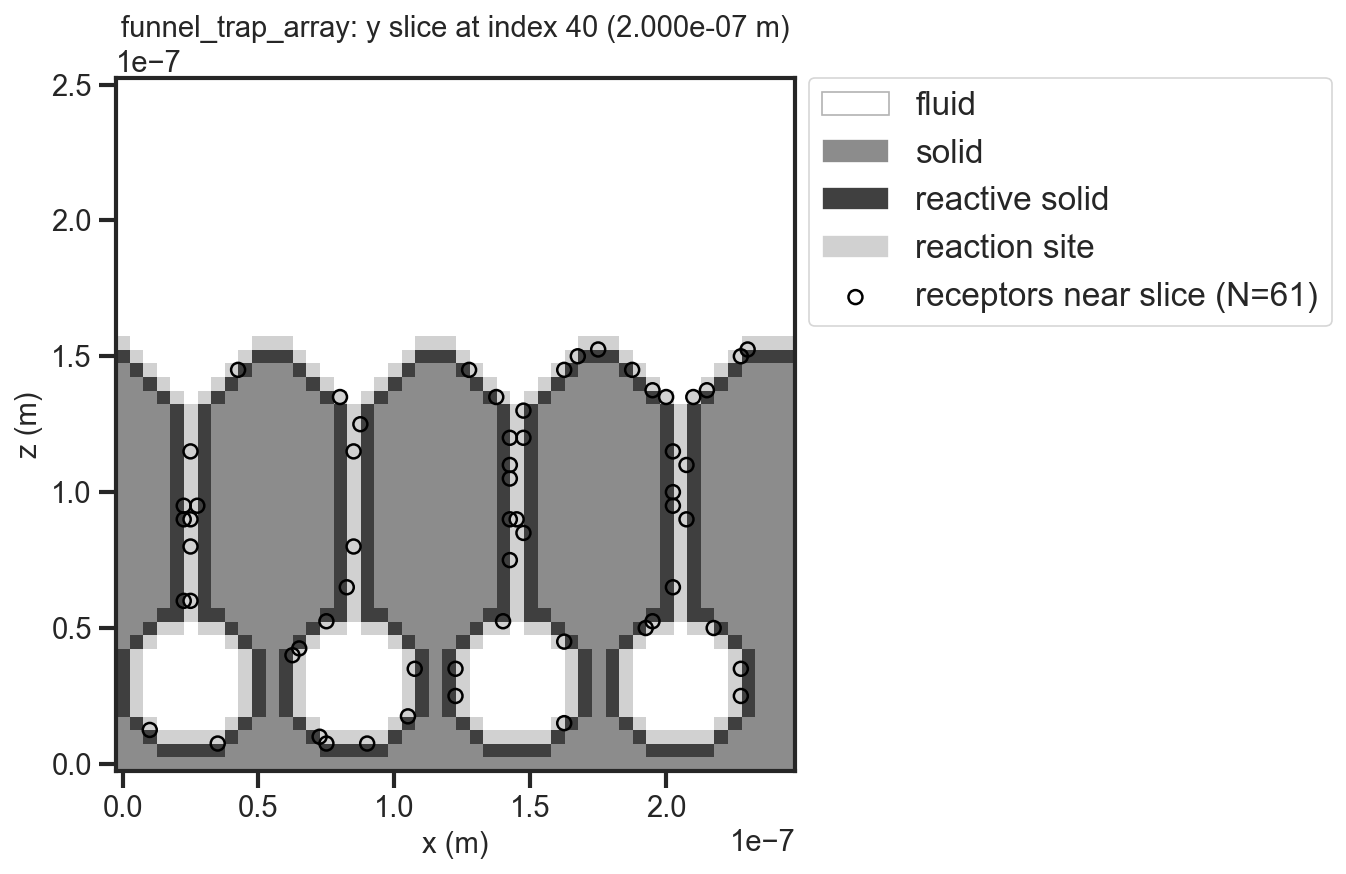

In [12]:
from utils.generate_geometries import make_funnel_trap_array_geometry

P_trap_array =  Params(
    Lx_m=0.25e-6,
    Ly_m=0.25e-6,
    H_m=0.25e-6,
    a_m=5e-9,

    D_m2_s=1e-11,
    receptor_density_m2=5e15,
    ligand_conc_M=10e-9,

    k_on_M_inv_s=1e6,
    k_off_s=1e-1,

    escape_distance_m=1e-6,

    use_well_mixed_reservoir=True,
    reservoir_offset_layers=1,

    seed=1,
)

trap_array_geometry = make_funnel_trap_array_geometry(
    P_trap_array,

    surface_z_m=150e-9,

    cavity_radius_m=25e-9,

    funnel_depth_m=20e-9,
    funnel_mouth_radius_m=25e-9,
    funnel_throat_radius_m=5e-9,

    throat_length_m=80e-9,

    pitch_m=60e-9,
    layout="square",

    reactive_region="all",
)

G_trap_array, S_trap_array = prepare_geometry_inspection(
    P_trap_array,
    geometry=trap_array_geometry,
)

plot_geometry_slice(
    P_trap_array,
    G=G_trap_array,
    S=S_trap_array,
    axis="y",
    coordinate_m=200e-9,
)